# Predicao de Churn com Rede Neural MLP

## IBM Telco Customer Churn

**Objetivo:** construir uma rede neural do tipo *Multilayer Perceptron* (MLP) para estimar a probabilidade de um cliente cancelar o servico.

O fluxo deste trabalho segue estas etapas:

1. carregar e conhecer os dados;
2. tratar inconsistencias e separar treino/teste;
3. preparar variaveis numericas e categoricas sem vazamento de dados;
4. treinar uma MLP para classificacao binaria;
5. avaliar o modelo com varias metricas;
6. investigar sinais de overfitting e underfitting.

> A classe positiva (`1`) representa **Churn = Yes**. Como deixar de detectar um cliente que vai cancelar pode ser caro, `recall`, F1 e ROC AUC devem ser analisados junto com a acuracia.

## 1. Bibliotecas e configuracao

In [2]:
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

DATA_PATH = Path("data/Telco-Customer-Churn.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Configuracao concluida.")

Configuracao concluida.


## 2. Carregamento e inspecao inicial dos dados

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset nao encontrado em {DATA_PATH}. Consulte as instrucoes do README.md."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dimensoes: {df.shape[0]:,} clientes e {df.shape[1]} colunas")
display(df.head())

Dimensoes: 7,043 clientes e 21 colunas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
resumo = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "ausentes": df.isna().sum(),
    "unicos": df.nunique(dropna=False),
})
display(resumo)
print(f"Linhas duplicadas completas: {df.duplicated().sum()}")
print("Valores da variavel-alvo:")
display(df["Churn"].value_counts(dropna=False).to_frame("quantidade"))

,tipo,ausentes,unicos
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


Linhas duplicadas completas: 0
Valores da variavel-alvo:


,quantidade
Churn,
No,5174
Yes,1869


### Observacao sobre `TotalCharges`

Embora represente um valor monetario, a coluna foi lida como texto. Isso acontece porque alguns clientes novos possuem espacos em branco nessa coluna. A conversao abaixo transforma esses espacos em valores ausentes; depois, o pipeline imputara a mediana aprendida **somente no treino**.

In [5]:
total_antes = df["TotalCharges"].dtype
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print(f"Tipo de TotalCharges: {total_antes} -> {df['TotalCharges'].dtype}")
print(f"Valores ausentes apos conversao: {df['TotalCharges'].isna().sum()}")
display(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().T)

Tipo de TotalCharges: object -> float64
Valores ausentes apos conversao: 11


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


## 3. Analise exploratoria

Taxa geral de churn: 26.54%


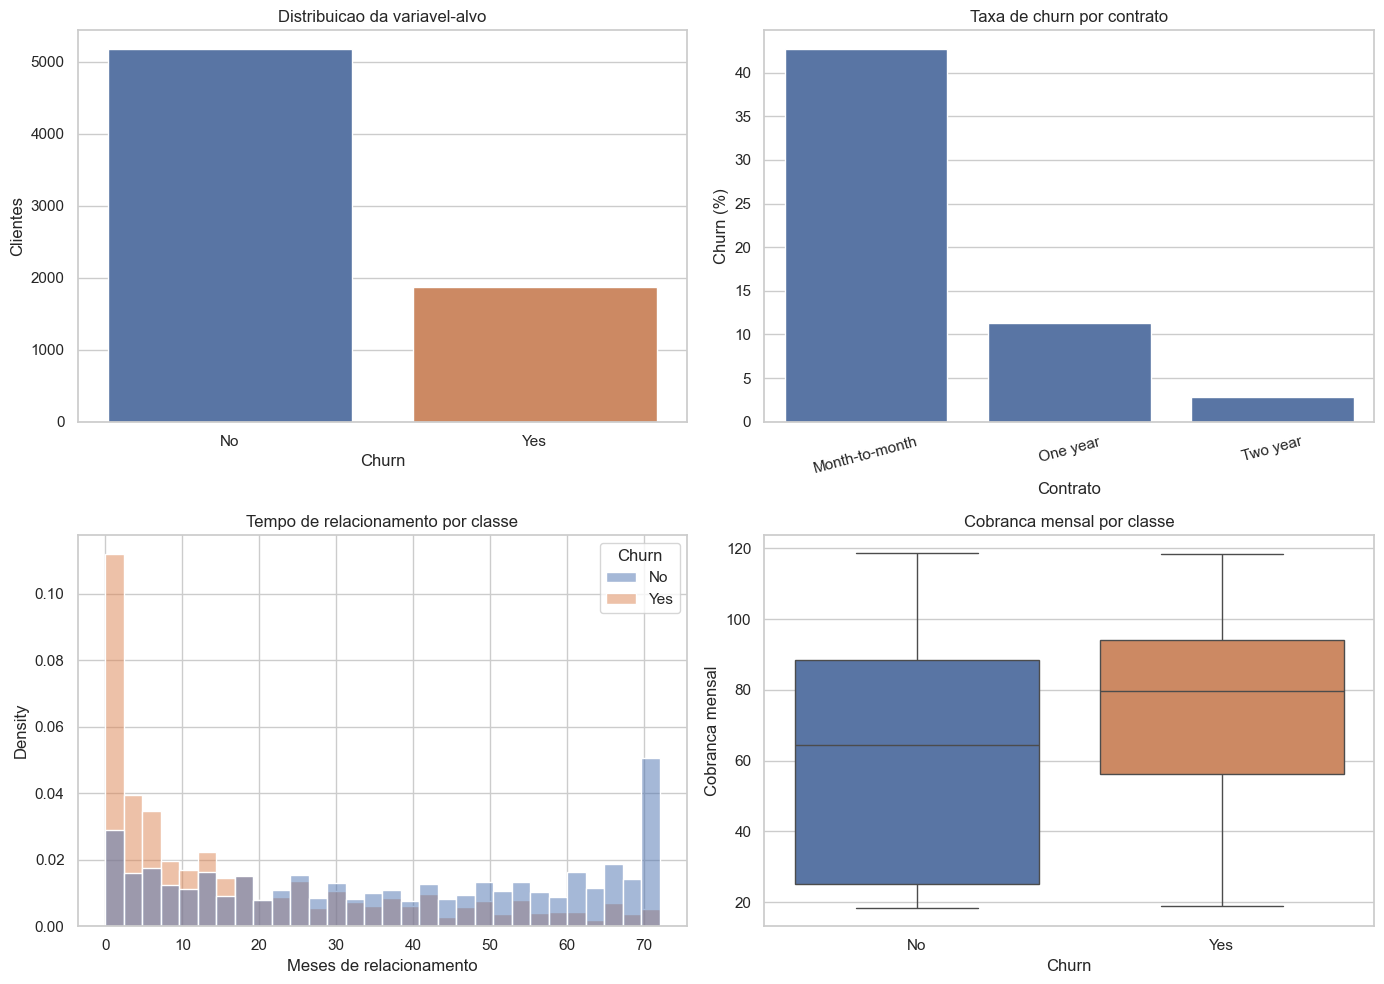

In [6]:
taxa_churn = df["Churn"].eq("Yes").mean()
print(f"Taxa geral de churn: {taxa_churn:.2%}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x="Churn", hue="Churn", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Distribuicao da variavel-alvo")
axes[0, 0].set_xlabel("Churn")
axes[0, 0].set_ylabel("Clientes")

contrato_churn = (
    df.assign(Churn_bin=df["Churn"].eq("Yes").astype(int))
      .groupby("Contract", observed=False)["Churn_bin"]
      .mean()
      .sort_values(ascending=False)
      .mul(100)
      .reset_index()
)
sns.barplot(data=contrato_churn, x="Contract", y="Churn_bin", ax=axes[0, 1])
axes[0, 1].set_title("Taxa de churn por contrato")
axes[0, 1].set_xlabel("Contrato")
axes[0, 1].set_ylabel("Churn (%)")
axes[0, 1].tick_params(axis="x", rotation=15)

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    multiple="layer",
    ax=axes[1, 0],
)
axes[1, 0].set_title("Tempo de relacionamento por classe")
axes[1, 0].set_xlabel("Meses de relacionamento")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Cobranca mensal por classe")
axes[1, 1].set_xlabel("Churn")
axes[1, 1].set_ylabel("Cobranca mensal")

plt.tight_layout()
plt.show()

**Leitura exploratoria:** a base e desbalanceada, pois a maioria dos clientes permanece. Contratos mensais, pouco tempo de relacionamento e valores mensais mais altos aparecem associados a churn. Essas associacoes sao descritivas e nao provam causalidade.

## 4. Separacao entre treino e teste

In [7]:
# customerID e apenas um identificador e nao deve ser usado como sinal preditivo.
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Treino: {X_train.shape[0]:,} registros")
print(f"Teste:  {X_test.shape[0]:,} registros")
print(f"Churn no treino: {y_train.mean():.2%}")
print(f"Churn no teste:  {y_test.mean():.2%}")

Treino: 5,634 registros
Teste:  1,409 registros
Churn no treino: 26.54%
Churn no teste:  26.54%


A divisao e feita antes de ajustar imputacao, codificacao ou escala. O parametro `stratify=y` preserva aproximadamente a proporcao de churn nos dois conjuntos, enquanto o conjunto de teste fica isolado para a avaliacao final.

## 5. Pre-processamento sem vazamento de dados

In [8]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [col for col in X.columns if col not in numeric_features]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

print(f"Variaveis numericas ({len(numeric_features)}): {numeric_features}")
print(f"Variaveis categoricas ({len(categorical_features)}): {categorical_features}")

Variaveis numericas (3): ['tenure', 'MonthlyCharges', 'TotalCharges']
Variaveis categoricas (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


- Numericas: valores ausentes recebem a mediana e, depois, sao padronizados. A escala e importante para a otimizacao por gradiente da MLP.
- Categoricas: valores ausentes recebem a moda e as categorias viram colunas binarias por *one-hot encoding*.
- `handle_unknown='ignore'` permite processar, no futuro, dados que nao contenham exatamente as mesmas categorias do treino.
- Todo o tratamento fica dentro de um `Pipeline`: durante o ajuste, os parametros sao aprendidos apenas com o treino.

## 6. Definicao e treinamento da MLP

In [9]:
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=32,
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    random_state=RANDOM_STATE,
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", mlp),
])

model.fit(X_train, y_train)

fitted_mlp = model.named_steps["classifier"]
print(fitted_mlp.out_activation_)
n_features_after_encoding = model.named_steps["preprocessor"].transform(X_train.iloc[:1]).shape[1]
print(f"Entradas apos codificacao: {n_features_after_encoding}")
print(f"Arquitetura: {n_features_after_encoding} -> 64 -> 32 -> 1")
print(f"Epocas executadas: {fitted_mlp.n_iter_} de no maximo {fitted_mlp.max_iter}")
print(f"Melhor acuracia na validacao interna: {fitted_mlp.best_validation_score_:.4f}")

logistic
Entradas apos codificacao: 46
Arquitetura: 46 -> 64 -> 32 -> 1
Epocas executadas: 26 de no maximo 300
Melhor acuracia na validacao interna: 0.8180


A rede possui duas camadas ocultas (64 e 32 neuronios) com ativacao ReLU. O otimizador Adam atualiza os pesos para reduzir a *log loss*. A regularizacao L2 (`alpha`) e a parada antecipada (`early_stopping`) ajudam a controlar overfitting. Para isso, 15% do conjunto de treino e usado internamente como validacao; o teste continua intocado.

## 7. Avaliacao do desempenho

In [10]:
def metricas_binarias(y_true, y_pred, y_prob):
    return {
        "acuracia": accuracy_score(y_true, y_pred),
        "precisao": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
    }

y_train_prob = model.predict_proba(X_train)[:, 1]
y_test_prob = model.predict_proba(X_test)[:, 1]
y_train_pred = (y_train_prob >= 0.50).astype(int)
y_test_pred = (y_test_prob >= 0.50).astype(int)

print("Metricas de desempenho do modelo:")
print("Probabilidades de treino:", y_train_prob)
print("Probabilidades de teste:", y_test_prob)
print("Predicoes de treino:", y_train_pred)
print("Predicoes de teste:", y_test_pred)

# Baseline: sempre prever a classe majoritaria (sem churn).
y_baseline = np.zeros_like(y_test)
baseline_prob = np.repeat(y_train.mean(), len(y_test))

metrics_df = pd.DataFrame({
    "treino": metricas_binarias(y_train, y_train_pred, y_train_prob),
    "teste": metricas_binarias(y_test, y_test_pred, y_test_prob),
    "baseline_majoritaria": metricas_binarias(y_test, y_baseline, baseline_prob),
}).T

display(metrics_df.style.format("{:.4f}"))
metrics_df.to_csv(OUTPUT_DIR / "metricas.csv", index_label="conjunto")

Metricas de desempenho do modelo:
Probabilidades de treino: [0.35253751 0.21985433 0.02740236 ... 0.47789488 0.03619449 0.19735291]
Probabilidades de teste: [0.03941855 0.73233596 0.05214202 ... 0.16107049 0.01032849 0.00929754]
Predicoes de treino: [0 0 0 ... 0 0 0]
Predicoes de teste: [0 1 0 ... 0 0 0]


,acuracia,precisao,recall,f1,roc_auc
treino,0.8085,0.7153,0.4622,0.5616,0.8537
teste,0.7984,0.6844,0.4465,0.5405,0.8428
baseline_majoritaria,0.7346,0.0000,0.0000,0.0000,0.5000


In [9]:
print("Relatorio de classificacao no teste (classe 1 = churn):")
report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Permanece", "Churn"],
        output_dict=True,
        zero_division=0,
    )
).T
display(report_df.style.format("{:.4f}"))

Relatorio de classificacao no teste (classe 1 = churn):


,precision,recall,f1-score,support
Permanece,0.8223,0.9256,0.8709,1035.0000
Churn,0.6844,0.4465,0.5405,374.0000
accuracy,0.7984,0.7984,0.7984,0.7984
macro avg,0.7534,0.6861,0.7057,1409.0000
weighted avg,0.7857,0.7984,0.7832,1409.0000


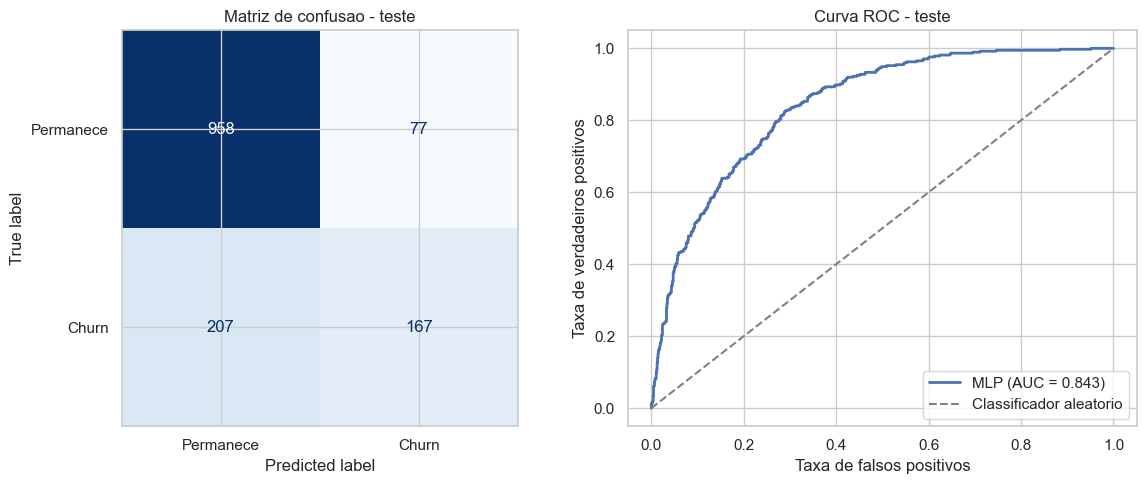

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Permanece", "Churn"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Matriz de confusao - teste")

fpr, tpr, _ = roc_curve(y_test, y_test_prob)
axes[1].plot(fpr, tpr, linewidth=2, label=f"MLP (AUC = {roc_auc_score(y_test, y_test_prob):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Classificador aleatorio")
axes[1].set(xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos", title="Curva ROC - teste")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

**Como interpretar as metricas:**

- **Acuracia:** proporcao total de acertos; pode parecer boa mesmo em dados desbalanceados.
- **Precisao:** entre os clientes marcados como churn, quantos realmente cancelaram.
- **Recall:** entre os clientes que cancelaram, quantos foram detectados. Falsos negativos reduzem o recall.
- **F1:** equilibrio entre precisao e recall.
- **ROC AUC:** capacidade de ordenar clientes de maior para menor risco em varios limiares; 0,5 corresponde ao acaso e 1,0 ao ranking perfeito.

O limiar de 0,50 e um ponto de partida. Em producao, ele deve ser escolhido conforme o custo de oferecer uma campanha de retencao e o custo de perder um cliente.

## 8. Overfitting e underfitting

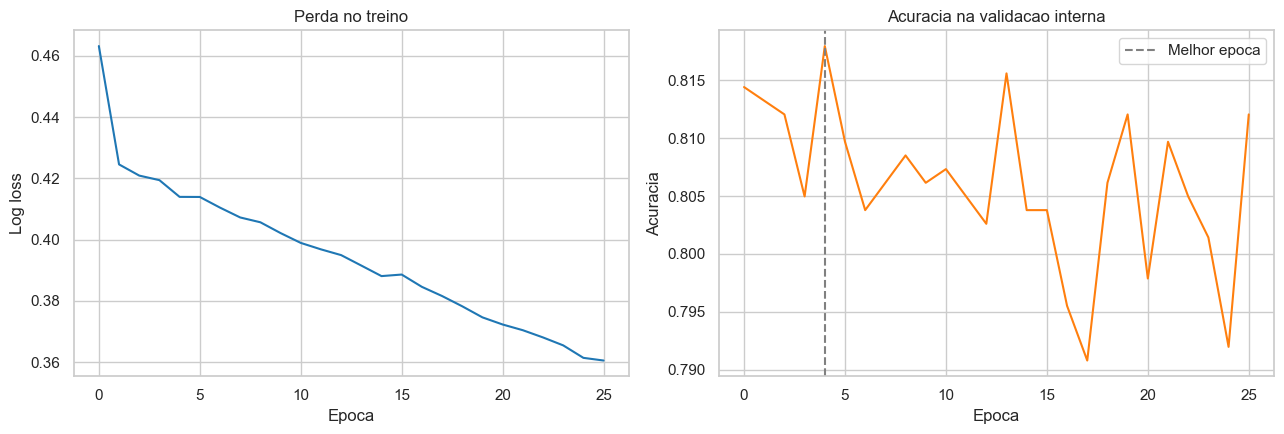

Gap treino-teste de acuracia: +0.0100
Gap treino-teste de F1:       +0.0211
Diagnostico: nao ha um gap grande entre treino e teste; nao aparece overfitting forte.
A ROC AUC de treino supera 0,70; nao ha sinal claro de underfitting severo.
A parada antecipada foi acionada quando a validacao deixou de melhorar.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(fitted_mlp.loss_curve_, color="tab:blue")
axes[0].set(title="Perda no treino", xlabel="Epoca", ylabel="Log loss")

axes[1].plot(fitted_mlp.validation_scores_, color="tab:orange")
axes[1].axvline(
    np.argmax(fitted_mlp.validation_scores_),
    linestyle="--",
    color="gray",
    label="Melhor epoca",
)
axes[1].set(title="Acuracia na validacao interna", xlabel="Epoca", ylabel="Acuracia")
axes[1].legend()

plt.tight_layout()
plt.show()

gap_acc = metrics_df.loc["treino", "acuracia"] - metrics_df.loc["teste", "acuracia"]
gap_f1 = metrics_df.loc["treino", "f1"] - metrics_df.loc["teste", "f1"]
print(f"Gap treino-teste de acuracia: {gap_acc:+.4f}")
print(f"Gap treino-teste de F1:       {gap_f1:+.4f}")

if gap_acc > 0.05 or gap_f1 > 0.05:
    print("Diagnostico: existe um gap relevante, indicando possivel overfitting.")
else:
    print("Diagnostico: nao ha um gap grande entre treino e teste; nao aparece overfitting forte.")

if metrics_df.loc["treino", "roc_auc"] < 0.70:
    print("A ROC AUC de treino e baixa, o que seria um sinal de underfitting.")
else:
    print("A ROC AUC de treino supera 0,70; nao ha sinal claro de underfitting severo.")

if fitted_mlp.n_iter_ < fitted_mlp.max_iter:
    print("A parada antecipada foi acionada quando a validacao deixou de melhorar.")

### Criterios usados no diagnostico

- **Overfitting:** desempenho muito melhor no treino do que no teste, enquanto a validacao para de melhorar. Possiveis acoes: aumentar `alpha`, reduzir a rede, coletar mais dados ou antecipar ainda mais a parada.
- **Underfitting:** desempenho fraco ate no treino. Possiveis acoes: aumentar a capacidade da rede, treinar por mais epocas, rever as variaveis ou reduzir regularizacao excessiva.
- Um pequeno gap e esperado. Os limites usados acima sao heuristicas didaticas, nao testes estatisticos.

Neste problema tabular, modelos de arvores com boosting tambem seriam bons candidatos para comparacao, mas a MLP foi mantida por ser o foco da atividade.

## 9. Salvamento dos artefatos

In [13]:
joblib.dump(model, OUTPUT_DIR / "modelo_churn_mlp.joblib")

previsoes = pd.DataFrame({
    "customerID": df.loc[X_test.index, "customerID"],
    "churn_real": y_test,
    "probabilidade_churn": y_test_prob,
    "churn_previsto": y_test_pred,
}).sort_values("probabilidade_churn", ascending=False)
previsoes.to_csv(OUTPUT_DIR / "previsoes_teste.csv", index=False)

print("Arquivos salvos:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"- {path} ({path.stat().st_size / 1024:.1f} KB)")

display(previsoes.head(10))

Arquivos salvos:
- outputs\metricas.csv (0.3 KB)
- outputs\modelo_churn_mlp.joblib (135.7 KB)
- outputs\previsoes_teste.csv (49.3 KB)


,customerID,churn_real,probabilidade_churn,churn_previsto
6866,0295-PPHDO,1,0.806095,1
2797,6023-YEBUP,1,0.804733,1
3727,9057-SIHCH,1,0.801796,1
3380,5178-LMXOP,1,0.791905,1
4039,8161-QYMTT,0,0.785952,1
4585,1069-XAIEM,1,0.784099,1
2519,4927-WWOOZ,0,0.783734,1
2246,7181-BQYBV,1,0.777888,1
3346,2545-EBUPK,0,0.777660,1
4678,3006-XIMLN,1,0.772655,1


## 10. Conclusoes

O pipeline transforma os dados brutos e produz uma probabilidade individual de churn. A avaliacao compara a MLP com uma baseline majoritaria e usa metricas apropriadas ao desbalanceamento. As curvas de treino/validacao, a parada antecipada e o gap treino-teste ajudam a verificar generalizacao.

Para uso real, ainda seriam necessarios: validacao temporal ou cruzada, escolha de limiar orientada a custos, analise de calibracao, explicabilidade, monitoramento de mudanca dos dados e avaliacao de vies por grupos de clientes. A predicao indica associacao estatistica; nao demonstra que uma intervencao causara a permanencia do cliente.